> **学生作业版说明**  
> 本 Notebook 为学生作业版，部分关键代码单元已被替换为待补全骨架。  
> 请结合 `README.md`、`assignment.md` 与 `starter.py` 完成实验。  
> 提交前请确认：代码可运行、指标齐全、报告完整。

In [1]:
import os, urllib.request
for f in ['spamTrain.mat', 'spamTest.mat']:
    if not os.path.exists(f):
        urllib.request.urlretrieve('https://raw.githubusercontent.com/Heptazero/ml-course-labs/main/machine-learning/homework/' + f, f)

In [2]:
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from scipy.io import loadmat
from sklearn.metrics import accuracy_score
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score

### 任务1：SoftSVM算法
#### 【任务目标】
实现软间隔支持向量机算法
#### 【任务步骤】
1. 继承SVM类
2. 重写get_H函数
3. 重写get_L函数

### SVM 基类
先定义实验七里的 SVM 基类，SoftSVM 继承它，只重写 get_H、get_L 加上惩罚参数 C。

In [3]:
class SVM:
    def get_H(self, Lambda, i, j, y):
        if y[i] == y[j]:
            return Lambda[i] + Lambda[j]
        else:
            return float("inf")

    def get_L(self, Lambda, i, j, y):
        if y[i] == y[j]:
            return 0.0
        else:
            return max(0, Lambda[j] - Lambda[i])

    def smo(self, X, y, K, N):
        m, n = X.shape
        Lambda = np.zeros(m)
        b = 0.0
        epsilon = 1e-6
        for t in range(N):
            for i in range(m):
                for j in range(m):
                    D_ij = 2 * K[i, j] - K[i, i] - K[j, j]
                    if abs(D_ij) < epsilon:
                        continue
                    E_i = K[:, i].dot(Lambda * y) + b - y[i]
                    E_j = K[:, j].dot(Lambda * y) + b - y[j]
                    delta_j = 1.0 * y[j] * (E_j - E_i) / D_ij
                    H = self.get_H(Lambda, i, j, y)
                    L = self.get_L(Lambda, i, j, y)
                    Lambda_j_old = Lambda[j]
                    Lambda[j] = np.clip(Lambda[j] + delta_j, L, H)
                    Lambda[i] = Lambda[i] + y[i] * y[j] * (Lambda_j_old - Lambda[j])
                    if Lambda[i] > epsilon:
                        b = y[i] - K[:, i].dot(Lambda * y)
                    elif Lambda[j] > epsilon:
                        b = y[j] - K[:, j].dot(Lambda * y)
        self.Lambda = Lambda
        self.b = b

    def fit(self, X, y, N=10):
        X = np.asarray(X, dtype=float)
        y = y.reshape(-1).astype(float)
        K = X.dot(X.T)
        self.smo(X, y, K, N)
        self.w = X.T.dot(self.Lambda * y)

    def predict(self, X):
        return np.sign(X.dot(self.w) + self.b)

In [4]:
"""
类说明：SoftSVM
    编写代码实现软间隔支持向量机算法

Parameters:
      Lambda   - 拉格朗日乘子
      i, j     - 分量
      y        - 标签
      C        - 控制惩罚强度的参数
Returns:
"""
class SoftSVM(SVM):
    def __init__(self, C = 1000):
        self.C = C
#####  Start Code Here  #####
    # 定义H_i,j
    def get_H(self, Lambda, i, j, y):
        if y[i] == y[j]:
            return min(self.C, Lambda[i] + Lambda[j])
        else:
            return min(self.C, self.C + Lambda[j] - Lambda[i])

    # 定义L_i,j
    def get_L(self, Lambda, i, j, y):
        if y[i] == y[j]:
            return max(0, Lambda[i] + Lambda[j] - self.C)
        else:
            return max(0, Lambda[j] - Lambda[i])

 #####  End Code Here  #####

### 任务2：软间隔支持向量机的次梯度下降算法
#### 【任务目标】
实现软间隔支持向量机的次梯度下降算法
#### 【任务步骤】
1. 由SoftSVMGD的构造函数传入控制惩罚强度的参数C
2. 定义模型训练的fit函数
3. 定义预测函数

In [5]:
"""
类说明：SoftSVMGD
    编写代码实现软间隔支持向量机算法

Parameters:
      C        - 控制惩罚强度的参数
      X        - 特征
      y        - 标签
     eta       - 学习速率
      N        - 搜索步数
Returns:
"""
class SoftSVMGD:
    def __init__(self, C = 1000):
        self.C = C

    # 定义模型训练的fit函数
    def fit(self, X, y, eta=0.01, N=5000):
#####  Start Code Here  #####
        m, n = X.shape
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        self.w = np.zeros(n)
        self.b = 0.0
        for t in range(N):
            margins = y * (X.dot(self.w) + self.b)
            M = margins < 1
            self.w -= eta * (self.w - self.C * X[M].T.dot(y[M]))
            self.b -= eta * (-self.C * y[M].sum())

#####  End Code Here  #####

    def predict(self, X):
        return np.sign(X.dot(self.w) + self.b)

### 任务3：软间隔支持向量机实现垃圾邮件分类

在练习文本中，有一个任务涉及一些文本预处理，以获得适合SVM处理的格式的数据。 然而，这个任务很简单（将字词映射到为练习提供的字典中的ID），而其余的预处理步骤（如HTML删除，词干，标准化等）已经完成。 我将跳过机器学习任务，而不是重现这些预处理步骤，其中包括从预处理过的训练集构建分类器，以及将垃圾邮件和非垃圾邮件转换为单词出现次数的向量的测试数据集。

你需要**将数据从文件`spamTrain.mat`和`spamTest.mat`中加载，并分别构建训练集和测试集**。

**要点**：
- 将你读入的数据输出
- 从数据中提取对应的`X, y, Xtest, ytest`
- 确保你的数据形状依次为：`(X(4000, 1899), y(4000,), Xtest(1000, 1899), ytest(1000,))`

In [6]:
#数据获取
spam_train = loadmat('spamTrain.mat')
spam_test = loadmat('spamTest.mat')

X_train = spam_train['X']
X_test = spam_test['Xtest']
y_train = spam_train['y'].ravel()
y_test = spam_test['ytest'].ravel()

每个文档已经转换为一个向量，其中1899个维对应于词汇表中的1899个单词。它们的值为二进制，表示文档中是否存在单词。

因此，训练评估是用一个分类器拟合测试数据的问题。

C = 0.1    test accuracy = 0.9920


C = 1      test accuracy = 0.9850


C = 10     test accuracy = 0.9860


C = 100    test accuracy = 0.9860


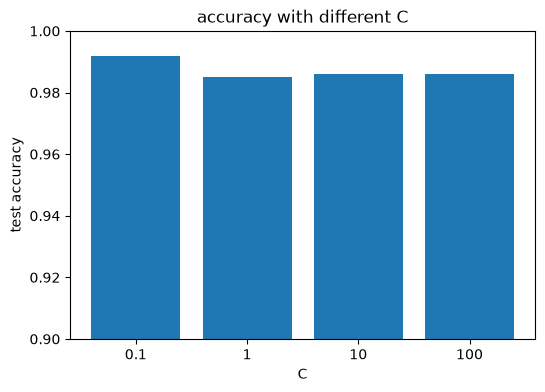

SoftSVM(SMO) 300 样本子集 accuracy = 0.9490


In [7]:
# 标签从 0/1 转成 -1/+1（先转 int，避免 uint8 减 1 时溢出）
y_train_svm = 2 * y_train.astype(int) - 1
y_test_svm = 2 * y_test.astype(int) - 1

# 用 SoftSVMGD 比较不同 C 的准确率
C_list = [0.1, 1, 10, 100]
acc_list = []
for C in C_list:
    model = SoftSVMGD(C=C)
    model.fit(X_train, y_train_svm, eta=0.01, N=1000)
    acc = accuracy_score(y_test, (model.predict(X_test) > 0).astype(int))
    acc_list.append(acc)
    print('C = %-5s  test accuracy = %.4f' % (C, acc))

# 画不同 C 的准确率
plt.figure(figsize=(6, 4))
plt.bar([str(c) for c in C_list], acc_list)
plt.xlabel('C')
plt.ylabel('test accuracy')
plt.ylim(0.9, 1.0)
plt.title('accuracy with different C')
plt.show()

# 取最好的 C 训练最终模型
model = SoftSVMGD(C=0.1)
model.fit(X_train, y_train_svm, eta=0.01, N=1000)
y_pred = (model.predict(X_test) > 0).astype(int)

# SoftSVM（SMO 版）在子集上验证，SMO 是 O(m^3)，全量数据跑不动
idx = np.random.RandomState(0).choice(len(X_train), 300, replace=False)
svm_small = SoftSVM(C=10)
svm_small.fit(X_train[idx], y_train_svm[idx], N=10)
print('SoftSVM(SMO) 300 样本子集 accuracy = %.4f' % accuracy_score(y_test, (svm_small.predict(X_test) > 0).astype(int)))

In [8]:
#计算指标
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print("accuracy = {}".format(accuracy))
print("precision = {}".format(precision))
print("recall = {}".format(recall))
print("f1 = {}".format(f1))

accuracy = 0.992
precision = 0.9838709677419355
recall = 0.9902597402597403
f1 = 0.9870550161812298
